[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohamedEsmat/CoolCairo/blob/master/analysis/notebooks/07_upgrade_results.ipynb)

# 07 · CoolCairo upgrade results: EnMAP materials and the targeted cooling plan

**Team 46 · Egypt** · Dr. Liquaa Mahmoud · Eng. Mohamed Esmat · Eng. Mahmoud Mostafa

This notebook recomputes the headline numbers of our upgrade pitch for Nasr City, east Cairo, with the same code the app and the full pipeline use. In Colab: **Runtime → Run all** (about 2 minutes, most of it installing packages). No account and no downloads beyond this public repository.

| Section | Pitch slide |
| --- | --- |
| 1 · What EnMAP sees in each block | Material map |
| 2 · Heat model, EnMAP vs Sentinel-2 | Putting it together · Methods |
| 3 · What each cooling measure does | Impact (one measure everywhere) |
| 4 · The targeted plan, −93 % | Impact |
| 5 · Sentinel-2 proof of concept, −83 % | What changed |

**Data.** The input is `export/district.json`, the file the app reads: 576 city blocks of 90 m with Landsat surface temperature, WorldPop residents, building footprints and heights, and the EnMAP material fractions of each block. EnMAP enters only as these per-block fractions (30 m pixels unmixed with our 47-pixel spectral library, averaged to 90 m blocks). The EnMAP licence does not allow sharing the imagery itself, so the steps that need the scene (unmixing, fitting the EnMAP heat model) are in `run_pipeline.py` and notebook 05 and need a free DLR account; their results are read here from `district.json`.

All temperatures are **land surface temperature** (Landsat, summer 2023–25), not air temperature.

In [1]:
# Google Colab only: fetch the repository and install CoolCairo's packages (1-2 minutes).
# Locally (uv, pip or conda, from the cloned repository) this cell does nothing.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("/content/CoolCairo"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/mohamedEsmat/CoolCairo.git", "/content/CoolCairo"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--ignore-requires-python",
                        "/content/CoolCairo/analysis"], check=True)
    sys.path.insert(0, "/content/CoolCairo/analysis/src")  # the repository's copy

In [2]:
import json, re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from coolcairo.config import REPO_ROOT, load_config
from coolcairo.enmap_materials import measure_deltas, plan_figures, treatable_areas
from coolcairo.population import heat_exposure

cfg = load_config()
district = json.loads((REPO_ROOT / "export" / "district.json").read_text(encoding="utf-8"))
enmap = district["enmap"]
snake = lambda k: re.sub(r"(?<!^)(?=[A-Z])", "_", k).lower()
blocks = pd.DataFrame({snake(k): v for k, v in district["blocks"].items()})
ROWS, COLS = district["rows"], district["cols"]
grid = lambda values: np.asarray(values, float).reshape(ROWS, COLS)  # row 0 = south

reference = district["model"]["heatReferenceC"]
print(f"{district['name']}: {len(blocks)} blocks of {district['blockSize']} m "
      f"({ROWS} x {COLS}), {blocks.population.sum():,.0f} residents (WorldPop 2024)")
print(f"EnMAP scene {enmap['sceneId'][:48]}..., acquired {enmap['acquired']}")
print(f"Spectral library: {enmap['library']}")
print(f"Typical east-Cairo block (heat reference): {reference:.2f} °C")

Nasr City: 576 blocks of 90 m (24 x 24), 95,141 residents (WorldPop 2024)
EnMAP scene ENMAP01-____L2A-DT0000127221_20250422T091720Z_00..., acquired 2025-04-22
Spectral library: 47 library pixels, each confirmed by eye (19 Nov 2026)
Typical east-Cairo block (heat reference): 45.85 °C


## 1 · What EnMAP sees in each block

Each 30 m EnMAP pixel is split into six materials with fully constrained unmixing (fractions ≥ 0 that sum to 1), using spectra of pixels we checked by eye one by one. The fractions are averaged to the 90 m blocks of the heat model. Sentinel-2 has 6 useful bands and confuses pale roofs, sand and dusty paving; EnMAP's ~200 bands tell them apart. **Asphalt, not sand, is the largest open hot surface** in Nasr City, which is why the plan moved from pocket parks to street measures.

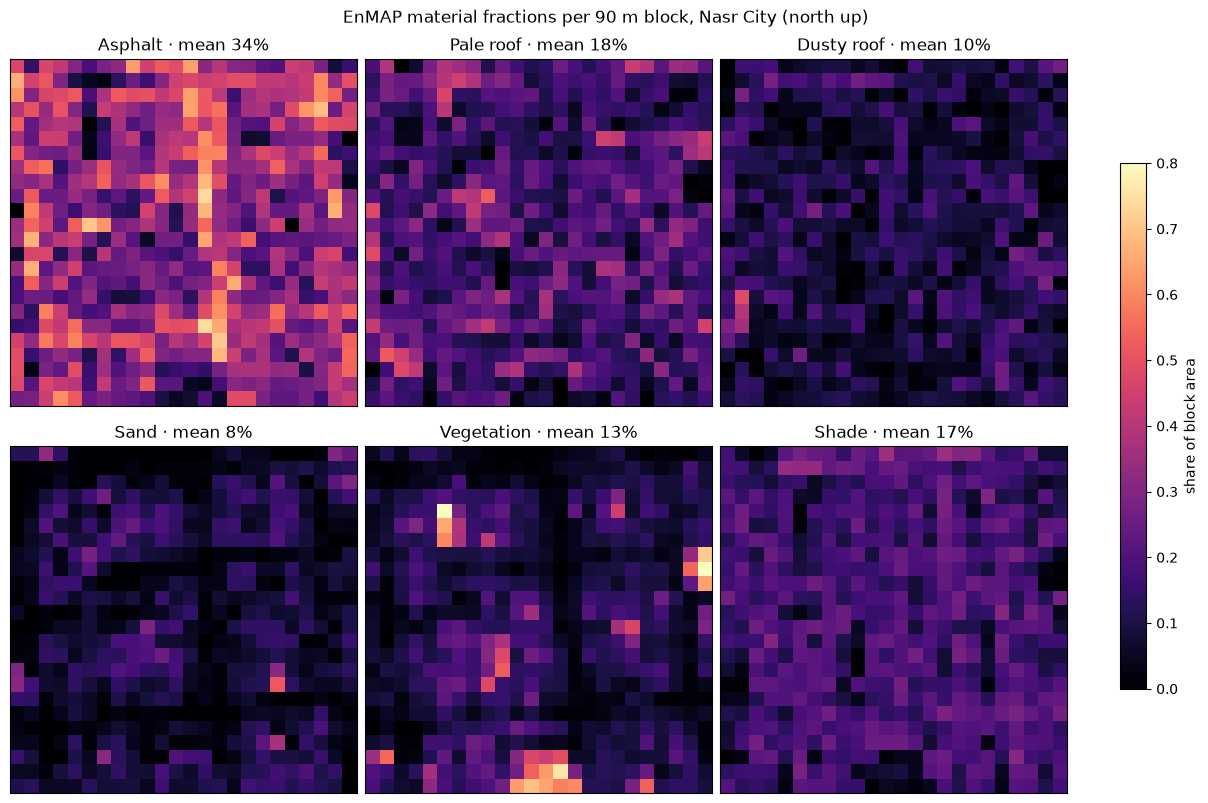

,mean share of block area
Asphalt,34%
Pale roof,18%
Shade,17%
Vegetation,13%
Dusty roof,10%
Sand,8%


In [3]:
materials = {"enmap_asphalt": "Asphalt", "enmap_pale_roof": "Pale roof", "enmap_dusty_roof": "Dusty roof",
             "enmap_sand": "Sand", "enmap_vegetation": "Vegetation", "enmap_shade": "Shade"}
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for ax, (col, name) in zip(axes.flat, materials.items()):
    im = ax.imshow(grid(blocks[col]), origin="lower", cmap="magma", vmin=0, vmax=0.8)
    ax.set_title(f"{name} · mean {blocks[col].mean():.0%}")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.7, label="share of block area")
fig.suptitle("EnMAP material fractions per 90 m block, Nasr City (north up)")
plt.show()

(blocks[list(materials)].mean().rename(materials).sort_values(ascending=False)
 .map("{:.0%}".format).rename("mean share of block area").to_frame())

## 2 · Heat model: EnMAP vs Sentinel-2

A linear model explains each block's summer surface temperature from what it is made of, fitted on **12,451 urban blocks** of east Cairo. The test is honest: whole 1 km tiles are hidden while the model learns and then predicted, because neighbouring blocks share heat. Same blocks, same tiles; only the material source changes. These results come from the full pipeline (it needs the EnMAP scene) and are stored in `district.json`.

In [4]:
print(f"Blocks in the model: {district['model']['nBlocks']:,}")
pd.DataFrame({
    "Sentinel-2 materials": [enmap["r2Sentinel2"], enmap["maeSentinel2"]],
    "EnMAP materials": [enmap["r2Enmap"], enmap["maeEnmap"]],
}, index=["R² (hidden 1 km tiles)", "mean error, °C"]).round(2)

Blocks in the model: 12,451


,Sentinel-2 materials,EnMAP materials
R² (hidden 1 km tiles),0.34,0.42
"mean error, °C",1.18,1.09


In [5]:
coef = pd.Series({"Pale roof": enmap["coefPaleRoof"], "Dusty roof": enmap["coefDustyRoof"],
                  "Asphalt": enmap["coefAsphalt"], "Vegetation": enmap["coefVegetation"],
                  "Shade": enmap["coefShade"]})
coef.round(2).rename("°C if the whole block were this material, vs sand").to_frame()

,"°C if the whole block were this material, vs sand"
Pale roof,0.41
Dusty roof,-2.10
Asphalt,-2.75
Vegetation,-7.77
Shade,-6.58


## 3 · What each cooling measure does

Cool roofs and cool pavements use the **albedo measured from our EnMAP library spectra** (how much sun each surface reflects today) and the published surface-temperature change per unit of albedo. Street trees and pocket parks use the EnMAP heat model. Limits: trees on up to 25 % of the asphalt, parks on up to 50 % of the sand.

**Heat exposure** = residents × degrees above the typical east-Cairo block (person·°C): a hot empty lot matters less than a hot block where many people live.

In [6]:
print("Albedo measured from the library spectra:", ", ".join(f"{name} {enmap[key]:.2f}" for name, key in
      (("pale roof", "albedoPaleRoof"), ("dusty roof", "albedoDustyRoof"),
       ("asphalt", "albedoAsphalt"), ("sand", "albedoSand"))))
pd.Series({"Cool roof (pale roof)": enmap["coolRoofPaleDeltaC"],
           "Cool roof (dusty roof)": enmap["coolRoofDustyDeltaC"],
           "Cool pavement": enmap["coolPavementDeltaC"],
           "Street trees": enmap["treesDeltaC"],
           "Pocket park": enmap["pocketParkDeltaC"]}).round(2).rename(
    "°C per unit of block area treated").to_frame()

Albedo measured from the library spectra: pale roof 0.35, dusty roof 0.27, asphalt 0.18, sand 0.34


,°C per unit of block area treated
Cool roof (pale roof),-2.79
Cool roof (dusty roof),-3.41
Cool pavement,-1.76
Street trees,-5.02
Pocket park,-7.77


In [7]:
figures = plan_figures(cfg, blocks, enmap, reference)
everywhere = pd.Series({"Cool pavements": figures["pctCoolPavements"], "Cool roofs": figures["pctCoolRoofs"],
                        "Street trees": figures["pctStreetTrees"], "Pocket parks": figures["pctPocketParks"]})
print(f"Heat exposure today: {figures['exposureBefore']:,.0f} person·°C")
everywhere.round(0).rename("% heat exposure, one measure in every block").to_frame()

Heat exposure today: 4,693 person·°C


,"% heat exposure, one measure in every block"
Cool pavements,-65.0
Cool roofs,-56.0
Street trees,-51.0
Pocket parks,-29.0


## 4 · The targeted plan: cool the riskiest third of blocks

Rank the blocks by today's heat exposure, take the top third (192 blocks) and apply **cool roofs + street trees + cool pavements** (the pavements cover the asphalt the trees leave). Because trees need water in Cairo, we also test a **no-water plan**: cool roofs + cool pavements only.

In [8]:
d = blocks.dropna(subset=["lst_c"])
people = d.population.clip(lower=0)
today = heat_exposure(d.lst_c, people, reference)
ranked = pd.DataFrame({"exposure": today, "lst": d.lst_c}).sort_values(
    ["exposure", "lst"], ascending=False, kind="stable")
chosen = ranked.index[: len(d) // 3]
deltas, area = measure_deltas(cfg, d, enmap), treatable_areas(d)
planted = cfg["interventions"]["tree_max_share_of_dark_ground"] * area.asphalt
plans = {"Targeted: roofs + trees + pavements":
             deltas.cool_roofs + deltas.street_trees + enmap["coolPavementDeltaC"] * (area.asphalt - planted),
         "No-water: roofs + pavements": deltas.cool_roofs + deltas.cool_pavements}
rows, after_lst = {}, {}
for name, delta in plans.items():
    change = pd.Series(0.0, index=d.index)
    change[chosen] = delta[chosen]
    after = heat_exposure(d.lst_c + change, people, reference)
    after_lst[name] = d.lst_c + change
    rows[name] = {"heat exposure after, person·°C": after.sum(),
                  "change %": 100 * (after.sum() - today.sum()) / today.sum(),
                  "treated blocks °C before": d.lst_c[chosen].mean(),
                  "treated blocks °C after": (d.lst_c + change)[chosen].mean(),
                  "residents in cooled blocks": people[change < -0.01].sum()}
hectares = (area.roof_pale + area.roof_dusty + area.asphalt)[chosen].sum() * (district["blockSize"] / 100) ** 2
print(f"{len(chosen)} of {len(d)} blocks treated · heat exposure today {today.sum():,.0f} person·°C · "
      f"about {hectares:.0f} ha of roof and asphalt coated or planted")
pd.DataFrame(rows).T.round({"heat exposure after, person·°C": 0, "change %": 1, "treated blocks °C before": 1,
                            "treated blocks °C after": 1, "residents in cooled blocks": 0})

192 of 576 blocks treated · heat exposure today 4,693 person·°C · about 97 ha of roof and asphalt coated or planted


,"heat exposure after, person·°C",change %,treated blocks °C before,treated blocks °C after,residents in cooled blocks
Targeted: roofs + trees + pavements,338.0,-92.8,45.9,44.2,22618.0
No-water: roofs + pavements,608.0,-87.0,45.9,44.5,22618.0


In [9]:
# The same figures the app shows (stored in district.json by the full pipeline): must agree.
assert abs(figures["targetedPct"] - enmap["targetedPct"]) < 0.01
assert abs(figures["targetedExposureAfter"] - enmap["targetedExposureAfter"]) < 0.1
assert abs(rows["Targeted: roofs + trees + pavements"]["change %"] - figures["targetedPct"]) < 1e-6
print(f"Check passed: {figures['targetedPct']:.1f} % here = {enmap['targetedPct']:.1f} % in the app "
      f"({figures['exposureBefore']:,.0f} -> {figures['targetedExposureAfter']:,.0f} person·°C, "
      f"{figures['targetedResidentsCooled']:,.0f} residents in cooled blocks)")

Check passed: -92.8 % here = -92.8 % in the app (4,693 -> 338 person·°C, 22,618 residents in cooled blocks)


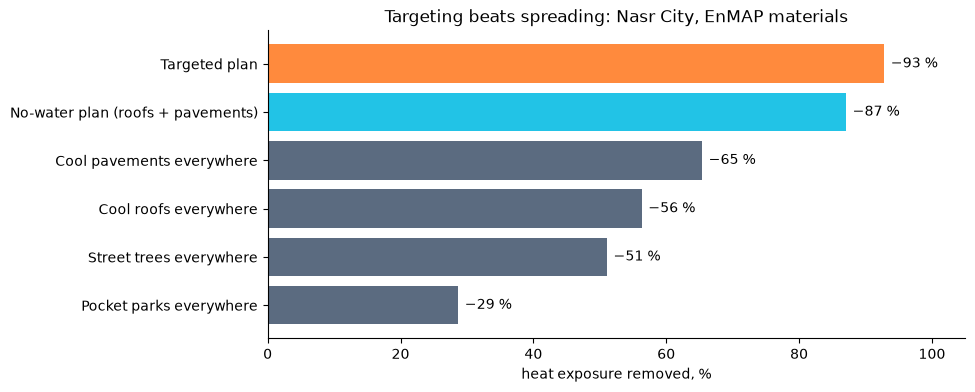

In [10]:
bars = pd.concat([pd.Series({"Targeted plan": figures["targetedPct"],
                             "No-water plan (roofs + pavements)": rows["No-water: roofs + pavements"]["change %"]}),
                  everywhere.rename(lambda s: s + " everywhere")])
fig, ax = plt.subplots(figsize=(9, 4))
colours = ["#FF8A3D", "#22C3E6"] + ["#5B6B80"] * len(everywhere)
ax.barh(bars.index[::-1], -bars.values[::-1], color=colours[::-1])
for y, v in enumerate(-bars.values[::-1]):
    ax.text(v + 1, y, f"−{v:.0f} %", va="center")
ax.set_xlabel("heat exposure removed, %"); ax.set_xlim(0, 105)
ax.set_title("Targeting beats spreading: Nasr City, EnMAP materials")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

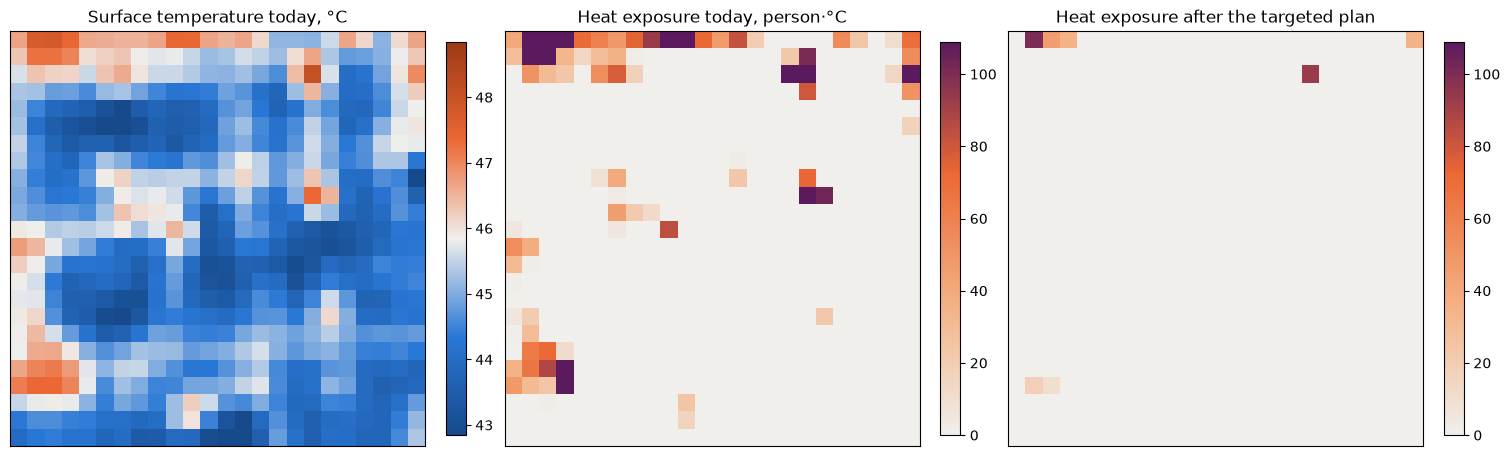

In [11]:
heat = LinearSegmentedColormap.from_list("heat", ["#174A8B", "#2A78D6", "#F0EFEC", "#EB6834", "#9C3A14"])
risk = LinearSegmentedColormap.from_list("risk", ["#F0EFEC", "#F4B183", "#EB6834", "#5B1A5E"])
plan_lst = after_lst["Targeted: roofs + trees + pavements"].reindex(blocks.index)
plan_exp = heat_exposure(plan_lst, people.reindex(blocks.index), reference)
today_full = today.reindex(blocks.index)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
panels = [(blocks.lst_c, heat, (reference - 3, reference + 3), "Surface temperature today, °C"),
          (today_full, risk, (0, np.nanpercentile(today_full, 98)), "Heat exposure today, person·°C"),
          (plan_exp, risk, (0, np.nanpercentile(today_full, 98)), "Heat exposure after the targeted plan")]
for ax, (values, cmap, (lo, hi), title) in zip(axes, panels):
    im = ax.imshow(grid(values), origin="lower", cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 5 · For comparison: the Sentinel-2 proof of concept

Before EnMAP, the same tool ran on Sentinel-2 materials for all 23,103 blocks of east Cairo (`data/sample_input/`, see notebook 00). There the large open hot surface looked like **sand**, so the plan was cool roofs + pocket parks. Same blocks, residents and temperatures:

In [12]:
from coolcairo.interventions import targeted_plan
from coolcairo.model import fit, training_rows

sample = pd.read_csv(REPO_ROOT / "data" / "sample_input" / "blocks_east_cairo.csv")
train = training_rows(sample, cfg["min_building_coverage"])
s2_model = fit(train, cfg["cv_tile_size"], cfg["cv_folds"])
s2 = targeted_plan(cfg, s2_model, sample[sample.in_display == 1], reference)
pd.DataFrame({
    "Sentinel-2 proof of concept": ["cool roofs + pocket parks", f"{s2['exposure_before']:,.0f}",
                                    f"{s2['exposure_after']:,.0f}", f"{s2['exposure_change_pct']:.0f} %"],
    "EnMAP upgrade": [figures["targetedMeasures"], f"{figures['exposureBefore']:,.0f}",
                      f"{figures['targetedExposureAfter']:,.0f}", f"{figures['targetedPct']:.0f} %"],
}, index=["targeted plan", "heat exposure today, person·°C", "after the plan", "change"])

,Sentinel-2 proof of concept,EnMAP upgrade
targeted plan,cool roofs + pocket parks,cool roofs + street trees + cool pavements
"heat exposure today, person·°C","4,693","4,693"
after the plan,778,338
change,-83 %,-93 %


## Summary: the pitch numbers, recomputed

| Pitch | Value | Where above |
| --- | --- | --- |
| Heat exposure today | 4,693 person·°C | §3, §4 |
| Targeted plan (riskiest third: roofs + trees + pavements) | **−93 %**, to 338 person·°C | §4 |
| Residents in cooled blocks | 22,618 | §4 |
| Treated blocks | 45.9 → 44.2 °C · about 97 ha | §4 |
| No-water plan (roofs + pavements) | −87 % | §4 |
| One measure everywhere | pavements −65 %, roofs −56 %, trees −51 %, parks −29 % | §3 |
| Heat model blocks | 12,451 · R² 0.34 → 0.42 with EnMAP | §2 |
| Sentinel-2 proof of concept | −83 % (roofs + parks) | §5 |

**Limits.** Surface temperature, not air temperature. The tree effect comes from the fitted model, not from measured street trees, so it is the least certain measure; the no-water plan does not depend on it. Full adoption within the limits above.

**Data and credits.** Contains modified EnMAP data © DLR [2025] · Landsat 8/9 (USGS) · Contains modified Copernicus Sentinel data [2023–2025] · WorldPop Global2 R2025A 2024 (CC BY 4.0) · © OpenStreetMap contributors (ODbL) · Google Open Buildings 2.5D Temporal (CC BY 4.0). Code: [github.com/mohamedEsmat/CoolCairo](https://github.com/mohamedEsmat/CoolCairo).